# Avance 1: Segmentación de clientes de tarjeta de crédito

**Curso:** Modelado y Presentación de Datos (Zegel)

**Integrantes:**
1. Hilario Vargas, Jorge Miguel
2. Mejía Hoyos, Juan Daniel
3. Villalobos Sánchez, Miguel Angel
4. Jacinto Hueda, Luis Alonso
5. Soto Santos, Renzo Gastón
6. Vera Espinoza, Paul Enrique

**Dataset:** *Default of Credit Card Clients* (UCI), 30 000 clientes de un emisor de tarjetas de Taiwán, abril a septiembre de 2005.

Cada sección corresponde a una diapositiva de la presentación. Al ejecutarlo:
- Las figuras se guardan en `reports/figures/`.
- Las cifras clave se guardan en `reports/resultados.json`.
- Los datos limpios con su segmento se guardan en `data/processed/`.

Para ejecutarlo: desde la raíz del proyecto, `jupyter notebook notebooks/avance1_segmentacion_clientes.ipynb` y luego *Run All*. Todas las rutas son relativas.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Rutas relativas: funciona tanto desde notebooks/ como desde la raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATOS = RAIZ / 'data' / 'raw' / 'UCI_Credit_Card.csv'
PROCESADOS = RAIZ / 'data' / 'processed'
FIGURAS = RAIZ / 'reports' / 'figures'
PROCESADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
resultados = {}      # cifras clave para la presentación


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f'{nombre}.png', dpi=150, bbox_inches='tight')

## Diapositiva 2: Problema y objetivos de negocio

**Problema.** Un emisor de tarjetas de crédito tiene una cartera de 30 000 clientes. El 22 % no paga su cuota al mes siguiente. Hoy aplica la misma política de límites, cobranza y ofertas a todos, aunque sus clientes se comportan de forma muy distinta. Así pierde dinero por impago en unos clientes y oportunidades de negocio con otros.

**Necesidad analítica.** Descubrir grupos de clientes con comportamiento de crédito parecido, sin usar la etiqueta de impago para formarlos, y comprobar después si esos grupos difieren en riesgo.

**Objetivos cuantitativos:**
1. Segmentar la cartera en 3 a 6 grupos interpretables con clustering (K-Means), eligiendo el número de grupos con criterios medibles: método del codo y coeficiente de silueta.
2. Identificar al menos un segmento con una tasa de impago de 1.5 veces el promedio o más.
3. Cuantificar el peso de cada segmento en clientes, en deuda y en impagos, para priorizar las acciones.

## Diapositiva 3: Carga de datos, origen y primer vistazo

- **Origen:** UCI Machine Learning Repository (Yeh, 2009), [doi:10.24432/C55S3H](https://doi.org/10.24432/C55S3H), licencia CC BY 4.0. Copia usada: [Hugging Face `scikit-learn/credit-card-clients`](https://huggingface.co/datasets/scikit-learn/credit-card-clients), licencia CC0.
- **Unidad de análisis:** un cliente. Los montos están en dólares de Taiwán (NT$).

In [2]:
df = pd.read_csv(DATOS)
print('Forma (filas, columnas):', df.shape)
resultados['filas_originales'], resultados['columnas_originales'] = df.shape
df.head()

Forma (filas, columnas): (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [4]:
# Inconsistencia de nombres: el estado de pago de septiembre se llama PAY_0,
# pero los meses siguientes son PAY_2 ... PAY_6. Se renombra a PAY_1 para que sea consistente.
df = df.rename(columns={'PAY_0': 'PAY_1', 'default.payment.next.month': 'impago'})

ESTADOS = [f'PAY_{i}' for i in range(1, 7)]        # 1 = septiembre ... 6 = abril
FACTURAS = [f'BILL_AMT{i}' for i in range(1, 7)]
PAGOS = [f'PAY_AMT{i}' for i in range(1, 7)]
MONTOS = ['LIMIT_BAL'] + FACTURAS + PAGOS

print('Tipos de dato:', df.dtypes.value_counts().to_dict())
print(f"Tasa de impago: {df['impago'].mean():.2%}")
resultados['tasa_impago_original'] = round(df['impago'].mean() * 100, 2)

Tipos de dato: {dtype('float64'): 13, dtype('int64'): 12}
Tasa de impago: 22.12%


**Diccionario resumido:**

| Grupo | Variables | Descripción |
|---|---|---|
| Crédito | `LIMIT_BAL` | Límite de crédito (NT$) |
| Demografía | `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Categóricas codificadas como números, y edad |
| Estado de pago | `PAY_1` a `PAY_6` | -1 = pagó a tiempo; 1 a 9 = meses de atraso. -2 y 0 no están documentados |
| Facturas | `BILL_AMT1` a `BILL_AMT6` | Monto facturado cada mes (1 = septiembre) |
| Pagos | `PAY_AMT1` a `PAY_AMT6` | Monto pagado cada mes |
| Objetivo | `impago` | 1 = no pagó el mes siguiente. **No se usa para formar los segmentos.** |

## Diapositiva 4: EDA univariado

In [5]:
df[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].describe().round(1)

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,30000.0,30000.0,30000.0,30000.0
mean,167484.3,35.5,51223.3,5663.6
std,129747.7,9.2,73635.9,16563.3
min,10000.0,21.0,-165580.0,0.0
25%,50000.0,28.0,3558.8,1000.0
50%,140000.0,34.0,22381.5,2100.0
75%,240000.0,41.0,67091.0,5006.0
max,1000000.0,79.0,964511.0,873552.0


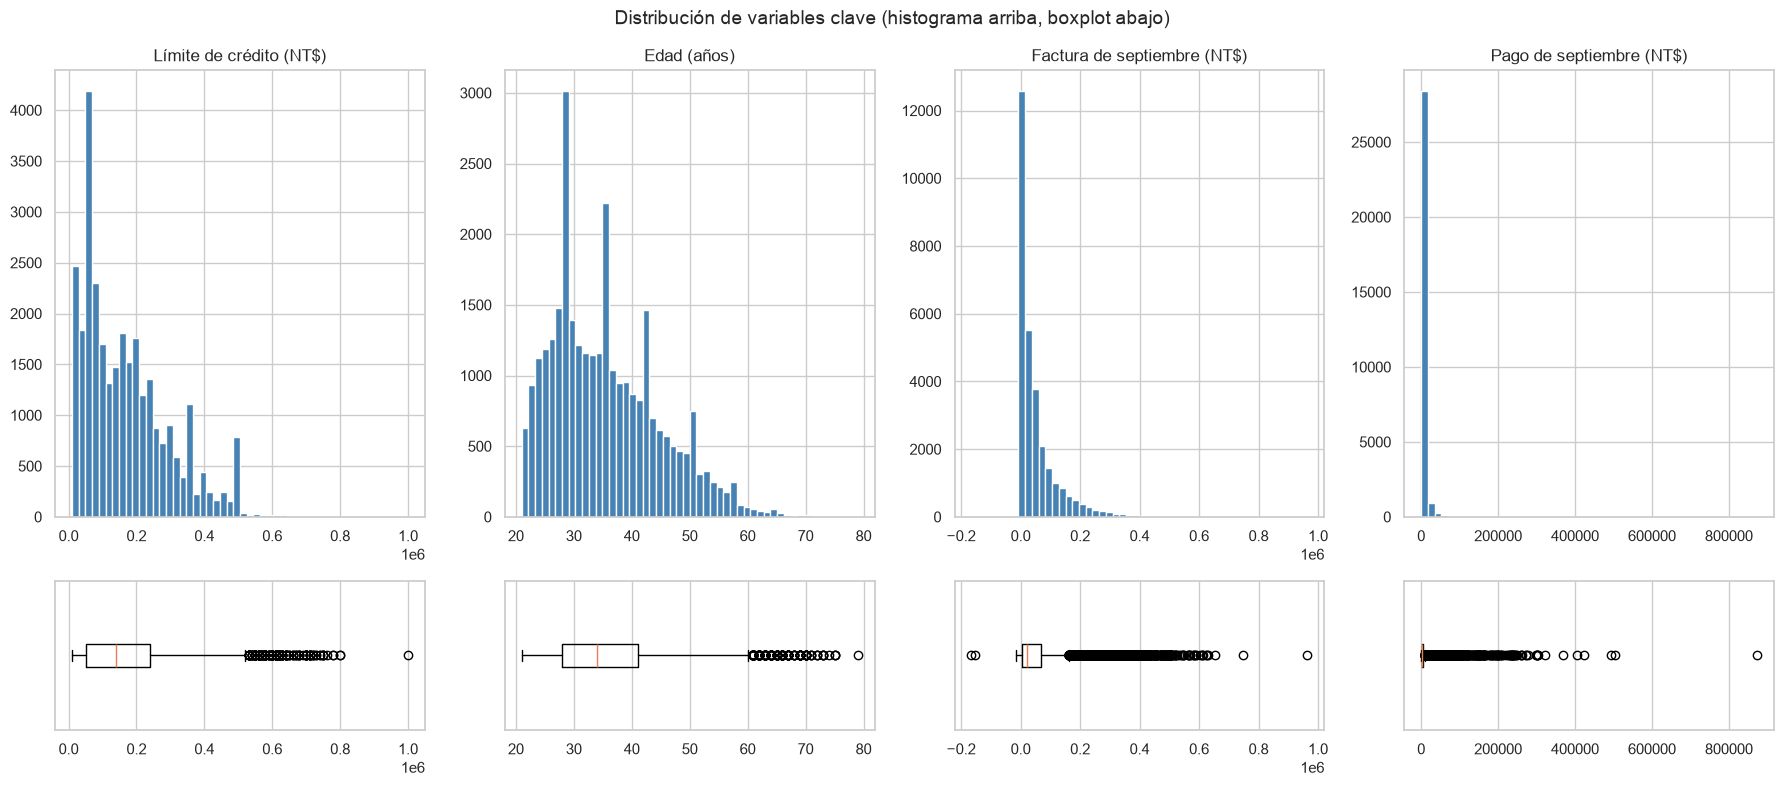

Asimetría (0 = simétrica; mayor que 1 = muy sesgada a la derecha):
LIMIT_BAL     0.99
AGE           0.73
BILL_AMT1     2.66
PAY_AMT1     14.67


In [6]:
claves = {
    'LIMIT_BAL': 'Límite de crédito (NT$)',
    'AGE': 'Edad (años)',
    'BILL_AMT1': 'Factura de septiembre (NT$)',
    'PAY_AMT1': 'Pago de septiembre (NT$)',
}
fig, axes = plt.subplots(2, 4, figsize=(18, 8), gridspec_kw={'height_ratios': [3, 1]})
for i, (col, titulo) in enumerate(claves.items()):
    axes[0, i].hist(df[col], bins=50, color='steelblue')
    axes[0, i].set_title(titulo)
    axes[1, i].boxplot(df[col], orientation='horizontal')
    axes[1, i].set_yticks([])
fig.suptitle('Distribución de variables clave (histograma arriba, boxplot abajo)', fontsize=14)
plt.tight_layout()
guardar(fig, 's04_distribuciones')
plt.show()

asimetria = df[list(claves)].skew().round(2)
print('Asimetría (0 = simétrica; mayor que 1 = muy sesgada a la derecha):')
print(asimetria.to_string())
resultados['asimetria'] = asimetria.to_dict()

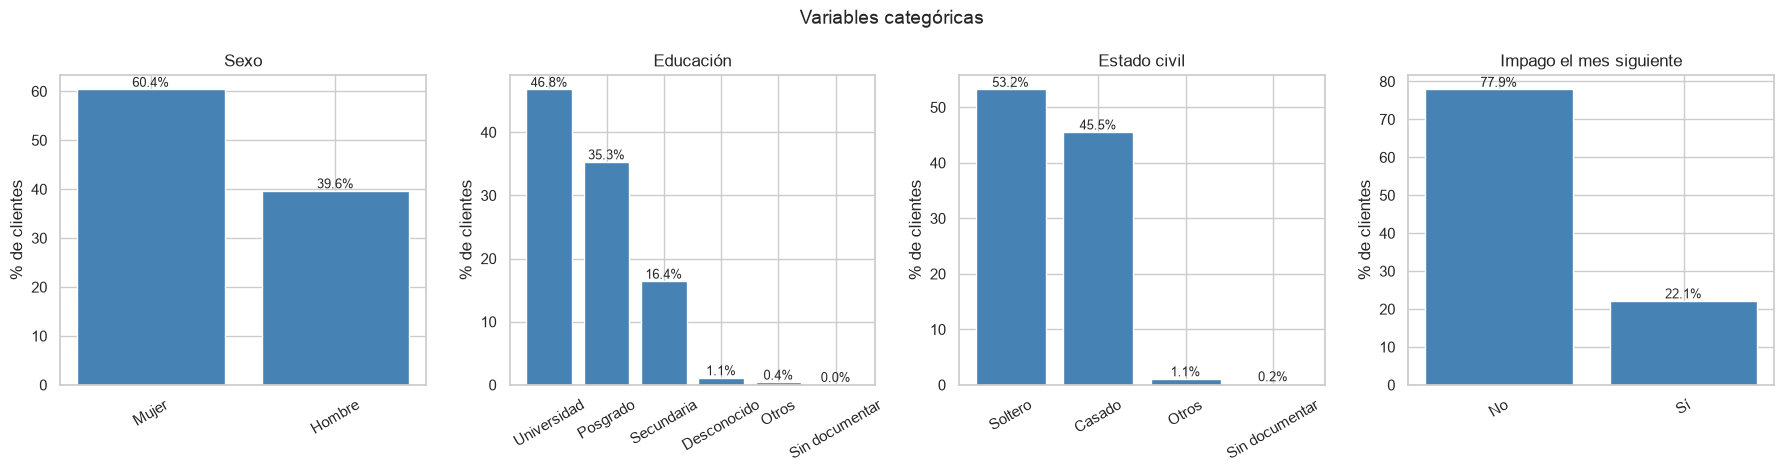

Mujeres: 60.4 % | Universidad: 46.8 %


In [7]:
ETIQUETAS = {
    'SEX': {1: 'Hombre', 2: 'Mujer'},
    'EDUCATION': {1: 'Posgrado', 2: 'Universidad', 3: 'Secundaria', 4: 'Otros',
                  5: 'Desconocido', 6: 'Desconocido', 0: 'Sin documentar'},
    'MARRIAGE': {1: 'Casado', 2: 'Soltero', 3: 'Otros', 0: 'Sin documentar'},
    'impago': {0: 'No', 1: 'Sí'},
}
TITULOS = {'SEX': 'Sexo', 'EDUCATION': 'Educación', 'MARRIAGE': 'Estado civil', 'impago': 'Impago el mes siguiente'}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (col, mapa) in zip(axes, ETIQUETAS.items()):
    porcentaje = df[col].map(mapa).value_counts(normalize=True) * 100
    ax.bar(porcentaje.index, porcentaje.values, color='steelblue')
    ax.bar_label(ax.containers[0], fmt='%.1f%%', fontsize=9)
    ax.set_title(TITULOS[col])
    ax.set_ylabel('% de clientes')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Variables categóricas', fontsize=14)
plt.tight_layout()
guardar(fig, 's04_categoricas')
plt.show()

resultados['pct_mujeres'] = round((df['SEX'] == 2).mean() * 100, 1)
resultados['pct_universidad'] = round((df['EDUCATION'] == 2).mean() * 100, 1)
print(f"Mujeres: {resultados['pct_mujeres']} % | Universidad: {resultados['pct_universidad']} %")

**Hallazgos univariados:**
- Las facturas y los pagos están **muy sesgados a la derecha**: la asimetría es 2.7 en la factura de septiembre y 14.7 en el pago. El límite está moderadamente sesgado (1.0). La mayoría de los clientes tiene montos bajos y unos pocos tienen montos muy altos. Esto anticipa atípicos y justifica una transformación logarítmica.
- La mitad de los clientes tiene entre 28 y 41 años (mediana: 34). El 60 % son mujeres y el 47 % tiene estudios universitarios.
- Hay códigos que el diccionario no documenta: educación 0/5/6 y estado civil 0. Se tratan en la diapositiva 6.
- Las clases están **desbalanceadas**: 22 % de impago frente a 78 % sin impago.

## Diapositiva 5: EDA multivariado

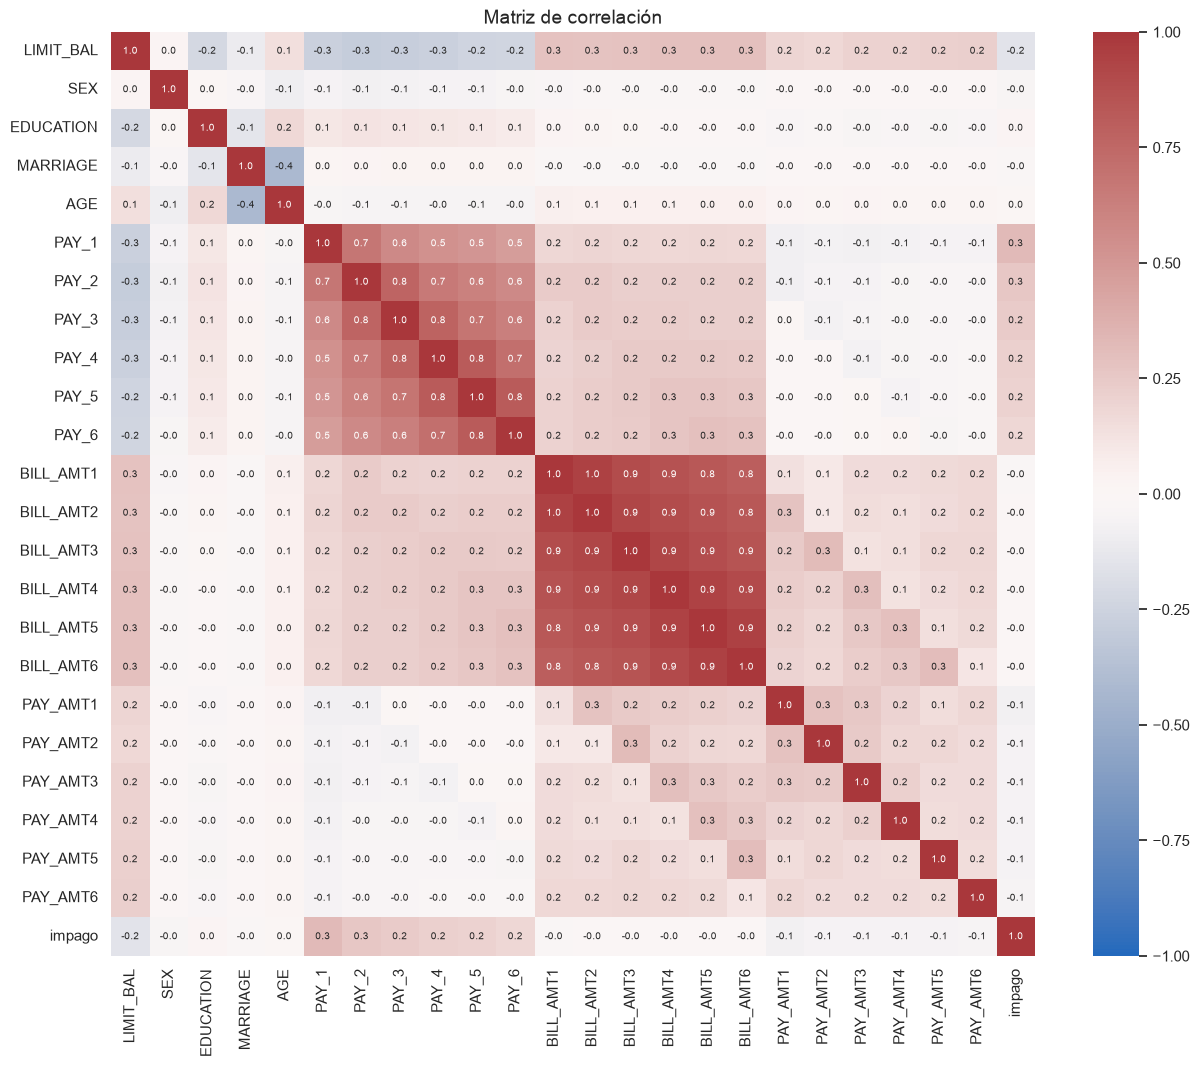

Pares más correlacionados:
BILL_AMT1  BILL_AMT2    0.951
BILL_AMT5  BILL_AMT6    0.946
BILL_AMT4  BILL_AMT5    0.940
BILL_AMT2  BILL_AMT3    0.928
BILL_AMT3  BILL_AMT4    0.924
BILL_AMT4  BILL_AMT6    0.901

Variables más correlacionadas con el impago:
PAY_1    0.325
PAY_2    0.264
PAY_3    0.235
PAY_4    0.217
PAY_5    0.204
PAY_6    0.187


In [8]:
corr = df.drop(columns='ID').corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f',
            annot_kws={'size': 7}, square=True, ax=ax)
ax.set_title('Matriz de correlación', fontsize=14)
guardar(fig, 's05_correlacion')
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
print('Pares más correlacionados:')
print(pares.head(6).round(3).to_string())
con_impago = corr['impago'].drop('impago')
con_impago = con_impago.reindex(con_impago.abs().sort_values(ascending=False).index)
print('\nVariables más correlacionadas con el impago:')
print(con_impago.head(6).round(3).to_string())
resultados['corr_facturas_consecutivas'] = round(corr.loc['BILL_AMT1', 'BILL_AMT2'], 3)
resultados['corr_impago_PAY_1'] = round(corr.loc['impago', 'PAY_1'], 3)
resultados['corr_impago_LIMIT_BAL'] = round(corr.loc['impago', 'LIMIT_BAL'], 3)

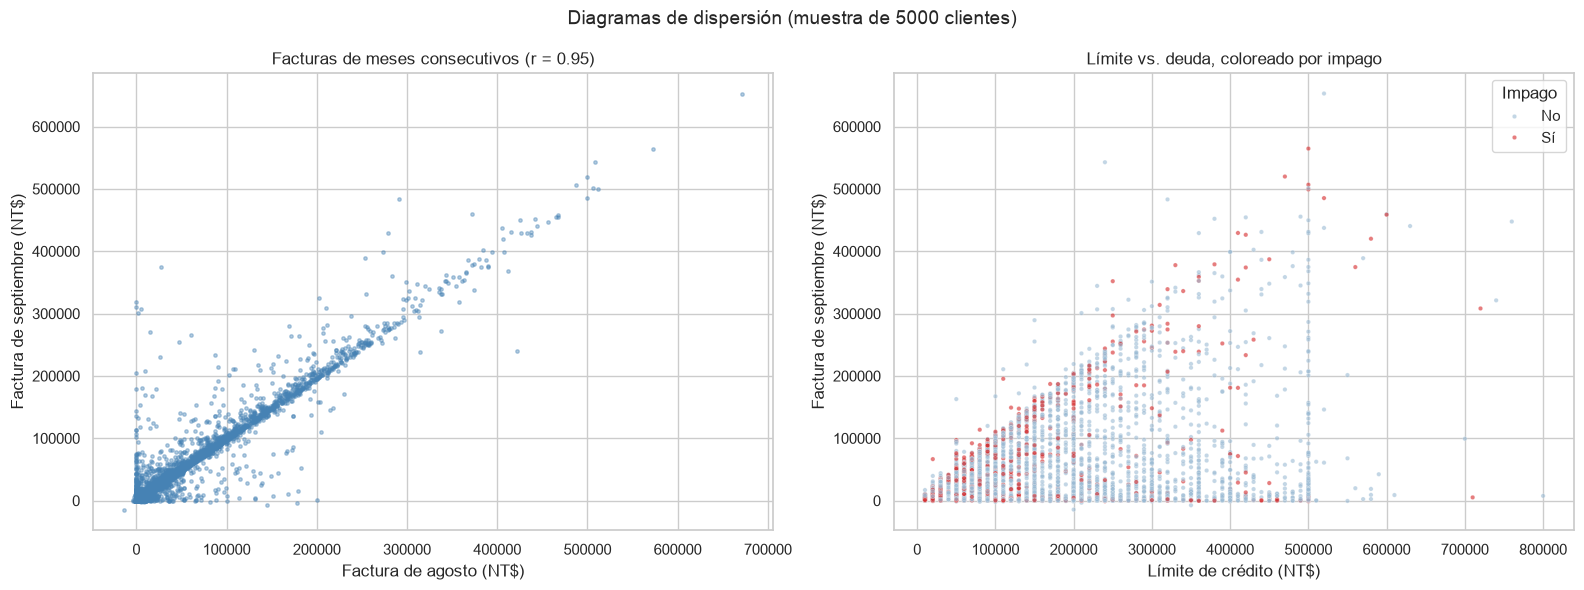

In [9]:
muestra = df.sample(5000, random_state=SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(muestra['BILL_AMT2'], muestra['BILL_AMT1'], s=6, alpha=0.4, color='steelblue')
axes[0].set(xlabel='Factura de agosto (NT$)', ylabel='Factura de septiembre (NT$)',
            title=f"Facturas de meses consecutivos (r = {corr.loc['BILL_AMT1', 'BILL_AMT2']:.2f})")
sns.scatterplot(data=muestra, x='LIMIT_BAL', y='BILL_AMT1', hue=muestra['impago'].map({0: 'No', 1: 'Sí'}),
                palette={'No': '#9bbbd4', 'Sí': '#d62728'}, s=10, alpha=0.6, ax=axes[1])
axes[1].set(xlabel='Límite de crédito (NT$)', ylabel='Factura de septiembre (NT$)',
            title='Límite vs. deuda, coloreado por impago')
axes[1].legend(title='Impago')
fig.suptitle('Diagramas de dispersión (muestra de 5000 clientes)', fontsize=14)
plt.tight_layout()
guardar(fig, 's05_dispersion')
plt.show()

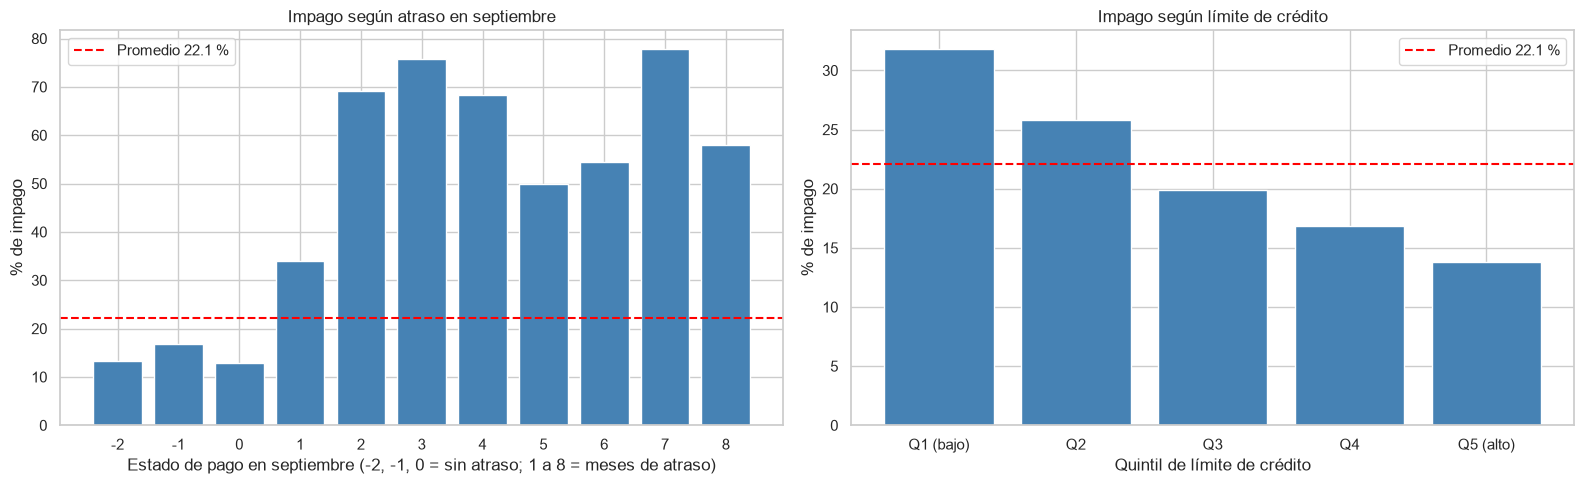

{'impago_sin_atraso_sep': np.float64(13.8), 'impago_con_2_meses_atraso_sep': np.float64(69.1), 'impago_quintil_limite_bajo': np.float64(31.8), 'impago_quintil_limite_alto': np.float64(13.8)}


In [10]:
promedio = df['impago'].mean() * 100
por_estado = df.groupby('PAY_1')['impago'].mean() * 100
df['quintil_limite'] = pd.qcut(df['LIMIT_BAL'], 5, labels=['Q1 (bajo)', 'Q2', 'Q3', 'Q4', 'Q5 (alto)'])
por_limite = df.groupby('quintil_limite', observed=True)['impago'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(por_estado.index.astype(str), por_estado.values, color='steelblue')
axes[0].axhline(promedio, color='red', linestyle='--', label=f'Promedio {promedio:.1f} %')
axes[0].set(xlabel='Estado de pago en septiembre (-2, -1, 0 = sin atraso; 1 a 8 = meses de atraso)',
            ylabel='% de impago', title='Impago según atraso en septiembre')
axes[0].legend()
axes[1].bar(por_limite.index.astype(str), por_limite.values, color='steelblue')
axes[1].axhline(promedio, color='red', linestyle='--', label=f'Promedio {promedio:.1f} %')
axes[1].set(xlabel='Quintil de límite de crédito', ylabel='% de impago', title='Impago según límite de crédito')
axes[1].legend()
plt.tight_layout()
guardar(fig, 's05_impago_por_grupo')
plt.show()
df = df.drop(columns='quintil_limite')

resultados['impago_sin_atraso_sep'] = round(df.loc[df['PAY_1'] <= 0, 'impago'].mean() * 100, 1)
resultados['impago_con_2_meses_atraso_sep'] = round(df.loc[df['PAY_1'] == 2, 'impago'].mean() * 100, 1)
resultados['impago_quintil_limite_bajo'] = round(por_limite.iloc[0], 1)
resultados['impago_quintil_limite_alto'] = round(por_limite.iloc[-1], 1)
print({k: resultados[k] for k in ['impago_sin_atraso_sep', 'impago_con_2_meses_atraso_sep',
                                  'impago_quintil_limite_bajo', 'impago_quintil_limite_alto']})

**Hallazgos multivariados:**
- Las facturas de meses consecutivos están **muy correlacionadas** (r = 0.92 a 0.95): las 18 columnas mensuales repiten información. Por eso, en la diapositiva 7, se resumen en pocas variables por cliente (promedios y ratios) antes de segmentar.
- El **atraso reciente** es la variable más asociada al impago (r = 0.32 con `PAY_1`). Los clientes con 2 meses de atraso en septiembre tienen un **69.1 %** de impago, frente al **13.8 %** de los clientes al día: cinco veces más.
- A **menor límite de crédito, mayor impago**: 31.8 % en el quintil de límite más bajo frente a 13.8 % en el más alto. El emisor ya asigna límites más bajos a los clientes de más riesgo, pero eso no basta.

## Diapositiva 6: Limpieza de datos (valores faltantes)

In [11]:
print('Nulos detectados por pandas:', int(df.isnull().sum().sum()))

duplicadas = df.drop(columns='ID').duplicated()
print('Filas duplicadas (todas las columnas iguales salvo el ID):', int(duplicadas.sum()))

# Los códigos fuera del diccionario son valores faltantes "disfrazados": se convierten en NaN
limpio = df.copy()
limpio['EDUCATION'] = limpio['EDUCATION'].where(~limpio['EDUCATION'].isin([0, 5, 6]))
limpio['MARRIAGE'] = limpio['MARRIAGE'].where(limpio['MARRIAGE'] != 0)
faltantes = limpio.isnull().sum()
faltantes = faltantes[faltantes > 0]
print('\nFaltantes después de recodificar:')
print(faltantes.to_string())

con_faltante = limpio[['EDUCATION', 'MARRIAGE']].isnull().any(axis=1)
resultados['duplicadas'] = int(duplicadas.sum())
resultados['faltantes_por_columna'] = faltantes.to_dict()
resultados['filas_con_faltante'] = int(con_faltante.sum())
resultados['pct_filas_con_faltante'] = round(con_faltante.mean() * 100, 2)
resultados['impago_filas_con_faltante'] = round(df.loc[con_faltante, 'impago'].mean() * 100, 1)
print(f"Filas con algún faltante: {con_faltante.sum()} ({con_faltante.mean():.2%})")

Nulos detectados por pandas: 0
Filas duplicadas (todas las columnas iguales salvo el ID): 35

Faltantes después de recodificar:
EDUCATION    345
MARRIAGE      54
Filas con algún faltante: 399 (1.33%)


Filas eliminadas: 434 (1.45%) | Quedan: 29,566
Tasa de impago: 22.12 % antes y 22.32 % después
Nulos restantes: 0


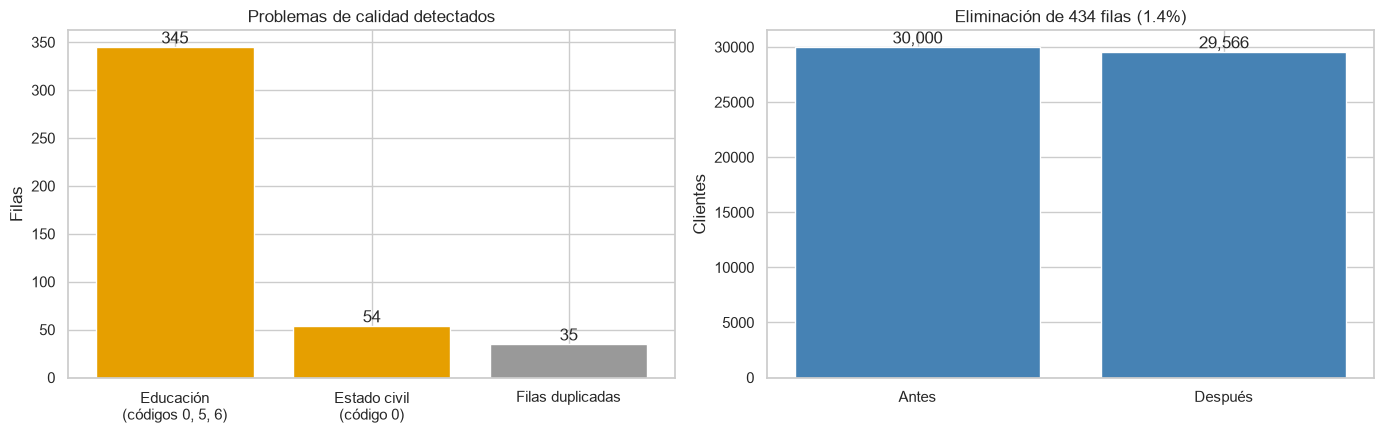

In [12]:
quitar = duplicadas | con_faltante
limpio = limpio[~quitar].reset_index(drop=True)
limpio[['EDUCATION', 'MARRIAGE']] = limpio[['EDUCATION', 'MARRIAGE']].astype(int)

resultados['filas_limpias'] = len(limpio)
resultados['filas_eliminadas'] = int(quitar.sum())
resultados['tasa_impago_limpia'] = round(limpio['impago'].mean() * 100, 2)
print(f"Filas eliminadas: {quitar.sum()} ({quitar.mean():.2%}) | Quedan: {len(limpio):,}")
print(f"Tasa de impago: {resultados['tasa_impago_original']} % antes y {resultados['tasa_impago_limpia']} % después")
print('Nulos restantes:', int(limpio.isnull().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
conteo = pd.Series({'Educación\n(códigos 0, 5, 6)': faltantes['EDUCATION'],
                    'Estado civil\n(código 0)': faltantes['MARRIAGE'],
                    'Filas duplicadas': duplicadas.sum()})
axes[0].bar(conteo.index, conteo.values, color=['#e69f00', '#e69f00', '#999999'])
axes[0].bar_label(axes[0].containers[0])
axes[0].set(ylabel='Filas', title='Problemas de calidad detectados')
axes[1].bar(['Antes', 'Después'], [len(df), len(limpio)], color='steelblue')
axes[1].bar_label(axes[1].containers[0], fmt='{:,.0f}')
axes[1].set(ylabel='Clientes', title=f'Eliminación de {quitar.sum()} filas ({quitar.mean():.1%})')
plt.tight_layout()
guardar(fig, 's06_faltantes')
plt.show()

**Metodología:**
1. `isnull().sum()` no encuentra nulos, pero el diccionario solo define educación 1 a 4 y estado civil 1 a 3. Los códigos educación 0/5/6 y estado civil 0 son **faltantes disfrazados**, así que se convierten en `NaN`.
2. Se encuentran **35 filas duplicadas** (idénticas salvo el ID).
3. **Tratamiento: eliminación.** Las filas afectadas son menos del 1.5 % y quedan más de 29 000 clientes. Además, las variables demográficas no se usan para segmentar. No se usa `ffill` porque los clientes no tienen orden temporal entre sí.
4. Los estados de pago -2 y 0 tampoco están documentados, pero aparecen en más de la mitad de las filas. Se conservan y se interpretan como "sin atraso", porque solo los valores de 1 a 9 indican meses de atraso.

## Diapositiva 7: Atípicos y transformación de variables

In [13]:
def pct_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).mean() * 100

atipicos = limpio[MONTOS].apply(pct_atipicos).round(1)
print('% de atípicos por regla IQR:')
print(atipicos.to_string())
negativas = (limpio[FACTURAS] < 0).any(axis=1)
print(f"\nClientes con alguna factura negativa (saldo a favor): {negativas.sum()}")
resultados['pct_atipicos_iqr'] = atipicos.to_dict()
resultados['clientes_factura_negativa'] = int(negativas.sum())

% de atípicos por regla IQR:
LIMIT_BAL     0.6
BILL_AMT1     8.0
BILL_AMT2     8.0
BILL_AMT3     8.2
BILL_AMT4     8.7
BILL_AMT5     9.1
BILL_AMT6     9.0
PAY_AMT1      9.1
PAY_AMT2      9.0
PAY_AMT3      8.6
PAY_AMT4     10.0
PAY_AMT5      9.8
PAY_AMT6      9.9

Clientes con alguna factura negativa (saldo a favor): 1909


In [14]:
# Variables de comportamiento por cliente (ingeniería de variables)
deuda = limpio[FACTURAS].clip(lower=0)                 # saldo a favor = sin deuda
var = pd.DataFrame(index=limpio.index)
var['limite'] = limpio['LIMIT_BAL']
var['factura_prom'] = deuda.mean(axis=1)
var['pago_prom'] = limpio[PAGOS].mean(axis=1)
var['utilizacion'] = var['factura_prom'] / var['limite']            # cuánto del límite usa
total_deuda = deuda.sum(axis=1)
var['ratio_pago'] = np.where(total_deuda > 0, limpio[PAGOS].sum(axis=1) / total_deuda.replace(0, np.nan), 1.0)
var['ratio_pago'] = var['ratio_pago'].clip(upper=1)                 # pagar más de lo facturado = 100 %
var['meses_atraso'] = (limpio[ESTADOS] > 0).sum(axis=1)             # meses con atraso (de 6)
var['atraso_max'] = limpio[ESTADOS].clip(lower=0).max(axis=1)       # peor atraso en meses

# Variación mensual de la deuda con pct_change (abril -> septiembre)
cronologico = limpio[FACTURAS[::-1]]
variacion = cronologico.T.pct_change().T.iloc[:, 1:]
n_inf = int(np.isinf(variacion).sum().sum())
n_nan = int(variacion.isna().sum().sum())
print(f'pct_change: {n_inf} infinitos (factura anterior en 0) y {n_nan} indefinidos (0/0) de {variacion.size}')
variacion = variacion.replace([np.inf, -np.inf], np.nan)
var['var_deuda'] = variacion.median(axis=1).clip(-1, 1).fillna(0)   # mediana mensual, acotada a ±100 %
resultados['pct_change_infinitos'] = n_inf
resultados['pct_change_indefinidos'] = n_nan
var.describe().round(3)

pct_change: 5156 infinitos (factura anterior en 0) y 10491 indefinidos (0/0) de 147830


,limite,factura_prom,pago_prom,utilizacion,ratio_pago,meses_atraso,atraso_max,var_deuda
count,29566.000,29566.000,29566.000,29566.000,29566.000,29566.000,29566.000,29566.000
mean,167507.735,44910.694,5264.090,0.373,0.346,0.841,0.687,-0.019
std,129956.898,63137.421,10140.737,0.352,0.381,1.560,1.076,0.339
min,10000.000,0.000,0.000,0.000,0.000,0.000,0.000,-1.000
25%,50000.000,4860.250,1116.667,0.030,0.043,0.000,0.000,-0.038
50%,140000.000,21006.583,2397.667,0.285,0.106,0.000,0.000,0.000
75%,240000.000,56975.667,5578.042,0.689,0.714,1.000,2.000,0.041
max,1000000.000,877313.833,627344.333,5.364,1.000,6.000,8.000,1.000


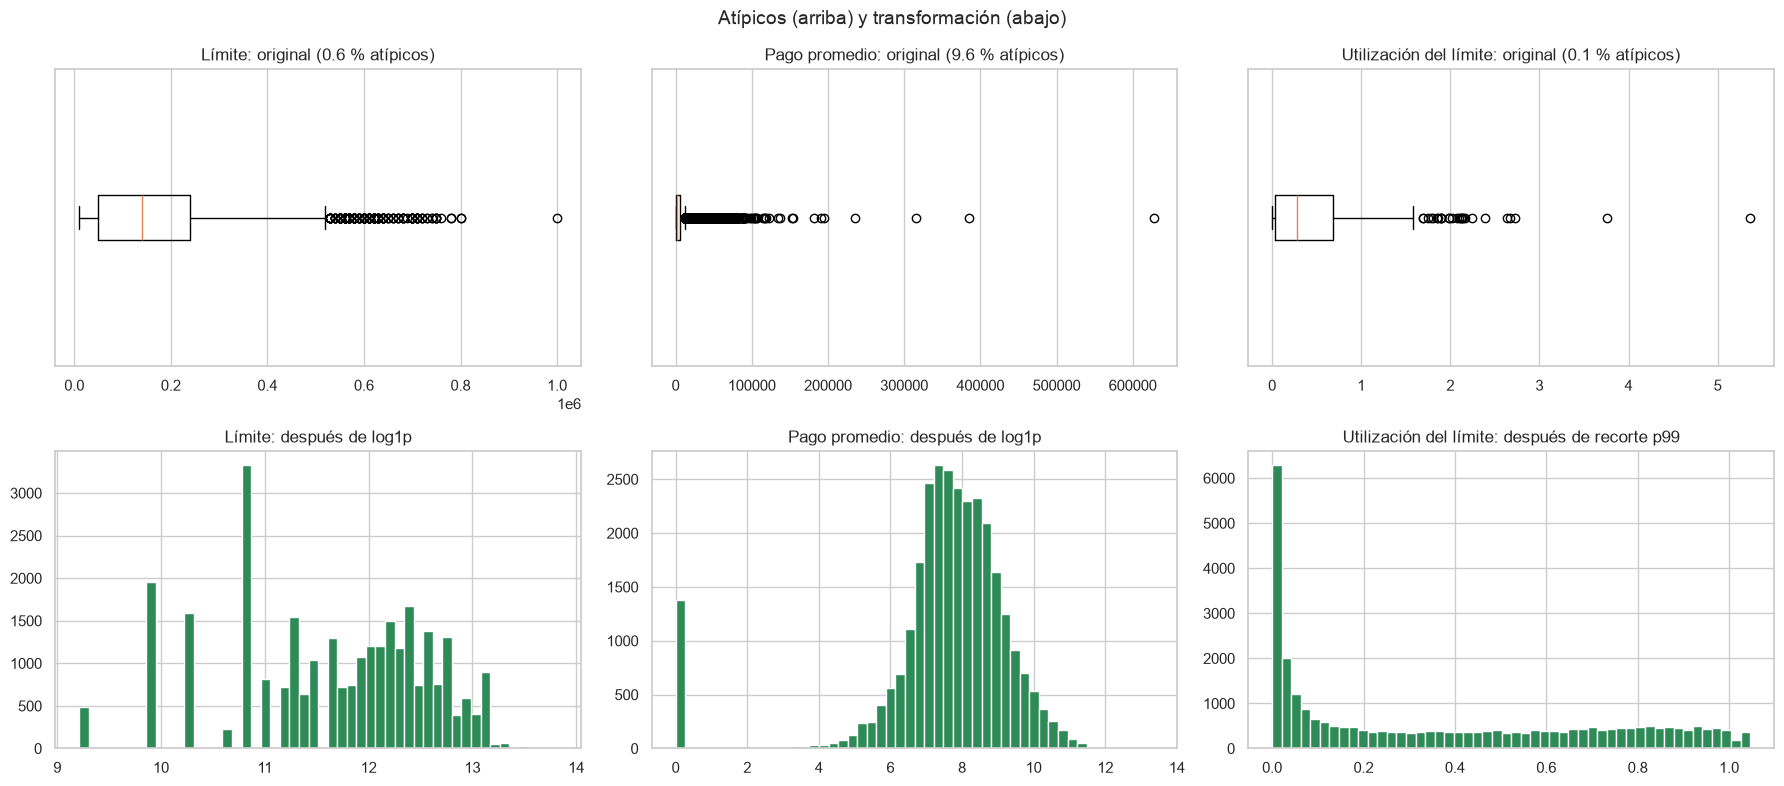

In [15]:
# Tratamiento: los atípicos son clientes reales (límites y pagos altos), no errores, así que no se eliminan.
#  - Montos: log1p para reducir el sesgo
#  - Utilización: recorte en el percentil 99 (hay clientes por encima de su límite)
p99_util = var['utilizacion'].quantile(0.99)
caracteristicas = pd.DataFrame({
    'log_limite': np.log1p(var['limite']),
    'utilizacion': var['utilizacion'].clip(upper=p99_util),
    'ratio_pago': var['ratio_pago'],
    'meses_atraso': var['meses_atraso'],
    'atraso_max': var['atraso_max'],
    'log_pago_prom': np.log1p(var['pago_prom']),
})
resultados['utilizacion_p99'] = round(p99_util, 3)
resultados['clientes_sobre_limite'] = int((var['utilizacion'] > 1).sum())

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for j, (orig, trans, nombre) in enumerate([('limite', 'log_limite', 'Límite'),
                                           ('pago_prom', 'log_pago_prom', 'Pago promedio'),
                                           ('utilizacion', 'utilizacion', 'Utilización del límite')]):
    axes[0, j].boxplot(var[orig], orientation='horizontal')
    axes[0, j].set_title(f'{nombre}: original ({pct_atipicos(var[orig]):.1f} % atípicos)')
    axes[0, j].set_yticks([])
    axes[1, j].hist(caracteristicas[trans], bins=50, color='seagreen')
    etiqueta = 'log1p' if trans.startswith('log') else 'recorte p99'
    axes[1, j].set_title(f'{nombre}: después de {etiqueta}')
fig.suptitle('Atípicos (arriba) y transformación (abajo)', fontsize=14)
plt.tight_layout()
guardar(fig, 's07_atipicos_transformacion')
plt.show()

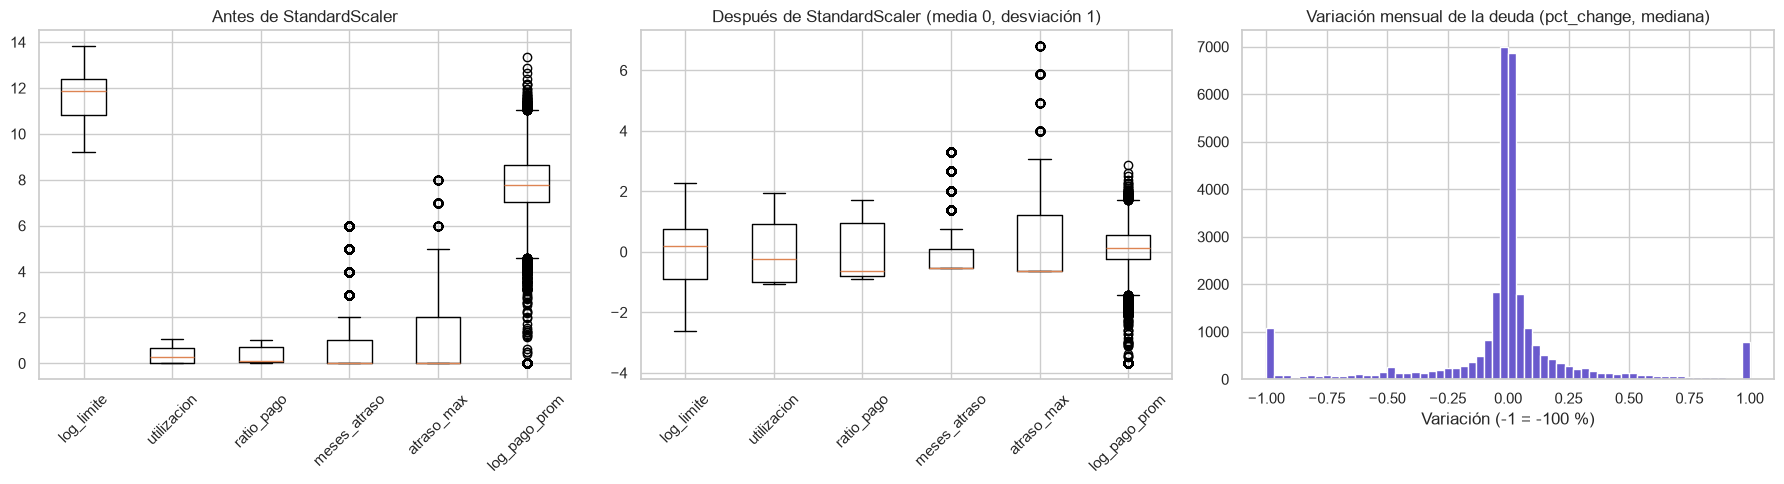

      log_limite  utilizacion  ratio_pago  meses_atraso  atraso_max  \
mean         0.0         -0.0         0.0           0.0         0.0   
std          1.0          1.0         1.0           1.0         1.0   

      log_pago_prom  
mean           -0.0  
std             1.0  


In [16]:
escalador = StandardScaler()
X = escalador.fit_transform(caracteristicas)
X_df = pd.DataFrame(X, columns=caracteristicas.columns)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].boxplot(caracteristicas.values, tick_labels=caracteristicas.columns)
axes[0].set_title('Antes de StandardScaler')
axes[0].tick_params(axis='x', rotation=45)
axes[1].boxplot(X, tick_labels=caracteristicas.columns)
axes[1].set_title('Después de StandardScaler (media 0, desviación 1)')
axes[1].tick_params(axis='x', rotation=45)
axes[2].hist(var['var_deuda'], bins=60, color='slateblue')
axes[2].set(title='Variación mensual de la deuda (pct_change, mediana)', xlabel='Variación (-1 = -100 %)')
plt.tight_layout()
guardar(fig, 's07_escalado_variacion')
plt.show()

print(X_df.describe().loc[['mean', 'std']].round(2))

**Metodología:**
- Entre 8 % y 10 % de las facturas y los pagos son atípicos por la regla IQR; en el límite, solo el 0.6 %. **No se eliminan**, porque son clientes reales con límites y pagos altos. Se aplica `log1p` para reducir el sesgo.
- 1909 clientes tienen alguna factura negativa, es decir, **saldo a favor**. Se trata como deuda 0.
- La utilización (deuda promedio / límite) supera el 100 % en algunos clientes, así que se **recorta en el percentil 99**.
- Con `pct_change` se calcula la **variación mensual de la deuda**. Las divisiones entre 0 dan infinitos: se convierten en `NaN`, se toma la mediana por cliente, se acota a ±100 % y los clientes sin variación calculable quedan en 0. Se usa para describir los segmentos.
- `StandardScaler` deja todas las variables en media 0 y desviación 1. Es imprescindible para K-Means, que agrupa por distancias: sin escalar, el límite (miles de NT$) dominaría sobre los meses de atraso (0 a 6).

## Diapositiva 8: Modelado no supervisado (clustering con K-Means)

La rúbrica pide aplicar **una** técnica: PCA o clustering, y en clustering, K-Means o jerárquico. Este proyecto usa **clustering con K-Means**.

**¿Por qué clustering y no PCA?**

| Criterio | PCA | Clustering |
|---|---|---|
| Qué entrega | Ejes continuos (componentes) que mezclan varias variables | Un segmento para cada cliente |
| ¿Responde al problema de negocio? | No directamente: no dice a qué clientes aplicar cada política | Sí: cada segmento puede recibir su propia política de límites y cobranza |
| Veredicto cuantitativo | Porcentaje de varianza explicada | Tasa de impago, deuda e impagos por segmento |
| ¿Hace falta en este dataset? | Poco: las 18 columnas mensuales ya se resumieron en 6 variables interpretables (diapositiva 7) | Sí: es el objetivo del análisis |

**¿Por qué K-Means y no jerárquico?**
- **Escala:** el jerárquico necesita las distancias entre todos los pares de clientes. Con casi 30 000 clientes son cientos de millones de distancias y varios GB de memoria (se calcula abajo). Solo sería viable con una muestra. K-Means procesa a todos los clientes en segundos.
- **Uso operativo:** K-Means asigna un segmento a clientes **nuevos** con `predict`, lo que sirve para operar la política y para el Avance 2. El jerárquico no tiene esa función.
- **Elección medible de k:** el método del codo y el coeficiente de silueta.
- **Limitaciones y cómo se manejan:**
  - Hay que elegir k: se usan el codo y la silueta.
  - Es sensible a la escala: se aplicó `StandardScaler`.
  - Depende de la inicialización: `n_init=10` y `random_state=42`.
  - Supone grupos compactos: la silueta mide qué tan bien se cumple.

In [17]:
n = len(X)
pares = n * (n - 1) // 2
memoria_gb = pares * 8 / 1e9
print(f'Clustering jerárquico con {n:,} clientes: {pares:,} distancias entre pares ≈ {memoria_gb:.1f} GB de memoria')
resultados['clientes_modelados'] = n
resultados['jerarquico_distancias'] = pares
resultados['jerarquico_memoria_gb'] = round(memoria_gb, 1)

Clustering jerárquico con 29,566 clientes: 437,059,395 distancias entre pares ≈ 3.5 GB de memoria


K-Means con 29,566 clientes, probando k de 2 a 8: 2.5 s en total


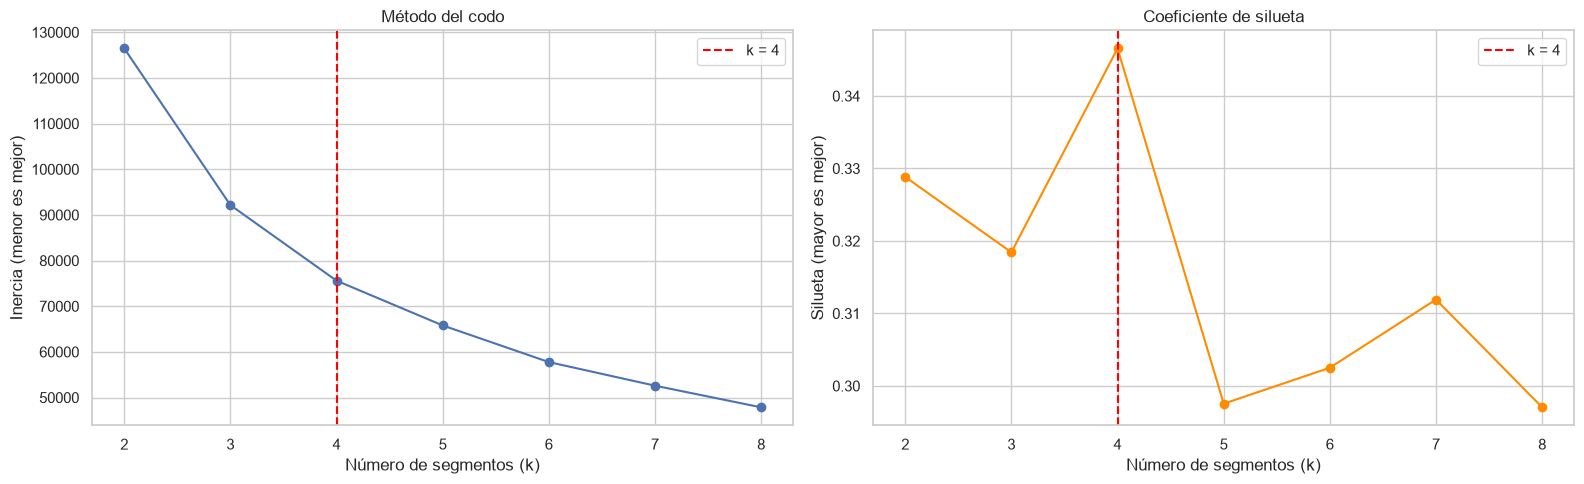

Silueta por k: {2: 0.329, 3: 0.318, 4: 0.347, 5: 0.298, 6: 0.303, 7: 0.312, 8: 0.297}
Caída de la inercia al sumar un segmento: {'2->3': 34320, '3->4': 16558, '4->5': 9800, '5->6': 8025, '6->7': 5173, '7->8': 4739}
k elegido: 4


In [18]:
rango_k = range(2, 9)
inercias, siluetas = [], []
inicio = time.perf_counter()
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=SEMILLA))
print(f'K-Means con {n:,} clientes, probando k de 2 a 8: {time.perf_counter() - inicio:.1f} s en total')
k_elegido = list(rango_k)[int(np.argmax(siluetas))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.plot(list(rango_k), inercias, marker='o')
ax1.axvline(k_elegido, color='red', linestyle='--', label=f'k = {k_elegido}')
ax1.set(xlabel='Número de segmentos (k)', ylabel='Inercia (menor es mejor)', title='Método del codo')
ax1.legend()
ax2.plot(list(rango_k), siluetas, marker='o', color='darkorange')
ax2.axvline(k_elegido, color='red', linestyle='--', label=f'k = {k_elegido}')
ax2.set(xlabel='Número de segmentos (k)', ylabel='Silueta (mayor es mejor)', title='Coeficiente de silueta')
ax2.legend()
plt.tight_layout()
guardar(fig, 's08_codo_silueta')
plt.show()

caidas = {f'{a}->{a + 1}': round(inercias[i] - inercias[i + 1]) for i, a in enumerate(list(rango_k)[:-1])}
resultados['inercias'] = {k: round(v) for k, v in zip(rango_k, inercias)}
resultados['caidas_inercia'] = caidas
resultados['siluetas'] = {k: round(s, 3) for k, s in zip(rango_k, siluetas)}
resultados['k_elegido'] = k_elegido
print('Silueta por k:', resultados['siluetas'])
print('Caída de la inercia al sumar un segmento:', caidas)
print('k elegido:', k_elegido)

**Elección de k = 4:**
- La **silueta es máxima en k = 4** (0.347).
- En el **codo**, la mejora se reduce después de k = 4: la inercia baja 16 558 al pasar de 3 a 4 segmentos y solo 9800 al pasar de 4 a 5.
- Una silueta de 0.35 indica una estructura **moderada**: los segmentos se diferencian, pero se solapan en parte. Es habitual en datos de comportamiento de clientes.

## Diapositiva 9: Los segmentos encontrados

Primero se describe quién está en cada segmento usando solo las variables con que se formaron. La etiqueta de impago se usa recién en la diapositiva 10, para validarlos.

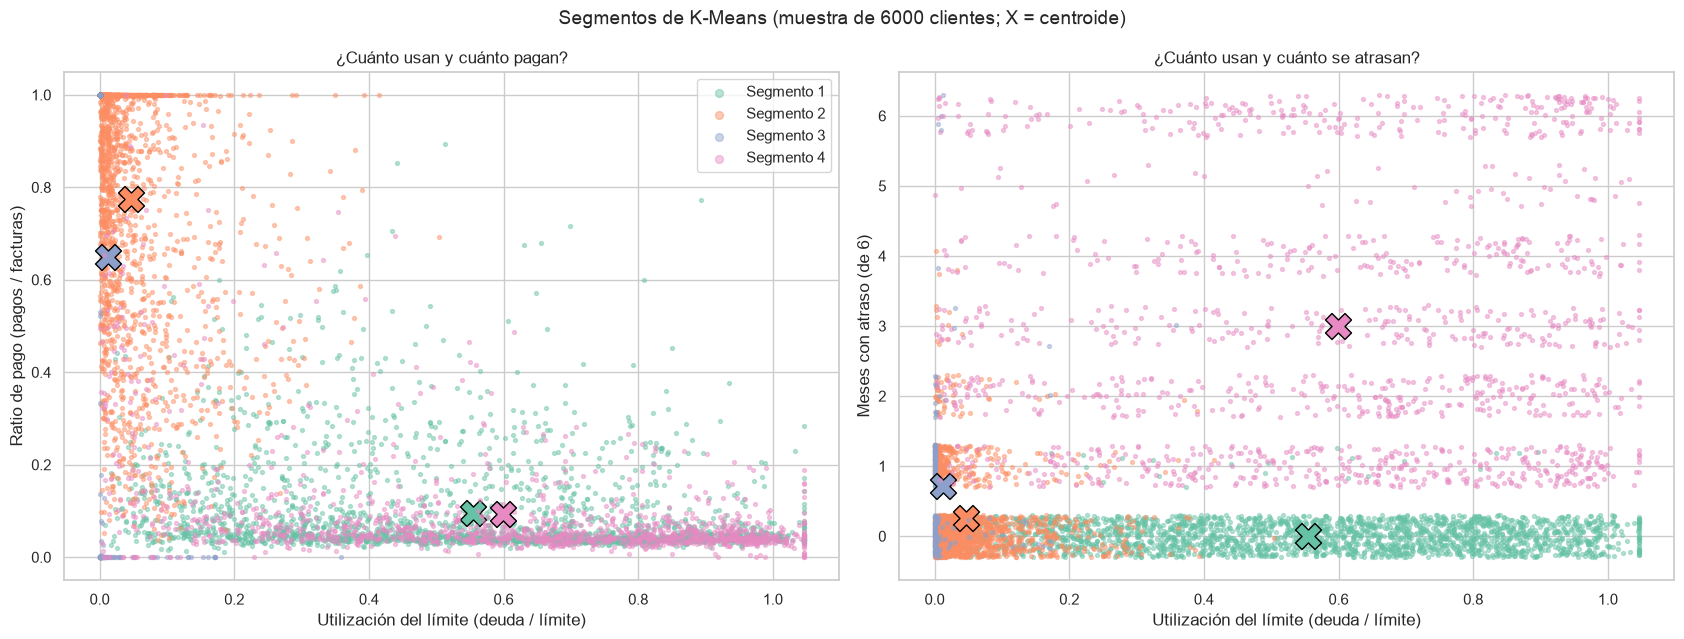

In [19]:
kmeans = KMeans(n_clusters=k_elegido, n_init=10, random_state=SEMILLA).fit(X)

# Se numeran los segmentos de menor a mayor impago para que el orden sea estable y fácil de leer.
# La etiqueta de impago NO participó en el clustering.
tasa_cluster = pd.Series(limpio['impago'].values).groupby(kmeans.labels_).mean().sort_values()
orden = {cluster: i + 1 for i, cluster in enumerate(tasa_cluster.index)}
segmento = pd.Series(kmeans.labels_).map(orden).values
limpio['segmento'] = segmento
colores = sns.color_palette('Set2', k_elegido)

# Centroides en la escala original de las variables
centros = pd.DataFrame(escalador.inverse_transform(kmeans.cluster_centers_), columns=caracteristicas.columns)
centros.index = [orden[c] for c in range(k_elegido)]
centros = centros.sort_index()

rng = np.random.default_rng(SEMILLA)
idx = rng.choice(n, size=6000, replace=False)
atraso_jitter = caracteristicas['meses_atraso'].values + rng.uniform(-0.3, 0.3, n)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for s in range(1, k_elegido + 1):
    m = segmento[idx] == s
    axes[0].scatter(caracteristicas['utilizacion'].values[idx][m], caracteristicas['ratio_pago'].values[idx][m],
                    s=8, alpha=0.45, color=colores[s - 1], label=f'Segmento {s}')
    axes[1].scatter(caracteristicas['utilizacion'].values[idx][m], atraso_jitter[idx][m],
                    s=8, alpha=0.45, color=colores[s - 1], label=f'Segmento {s}')
    axes[0].scatter(centros.loc[s, 'utilizacion'], centros.loc[s, 'ratio_pago'], s=350, marker='X',
                    color=colores[s - 1], edgecolor='black')
    axes[1].scatter(centros.loc[s, 'utilizacion'], centros.loc[s, 'meses_atraso'], s=350, marker='X',
                    color=colores[s - 1], edgecolor='black')
axes[0].set(xlabel='Utilización del límite (deuda / límite)', ylabel='Ratio de pago (pagos / facturas)',
            title='¿Cuánto usan y cuánto pagan?')
axes[1].set(xlabel='Utilización del límite (deuda / límite)', ylabel='Meses con atraso (de 6)',
            title='¿Cuánto usan y cuánto se atrasan?')
axes[0].legend(markerscale=2)
fig.suptitle('Segmentos de K-Means (muestra de 6000 clientes; X = centroide)', fontsize=14)
plt.tight_layout()
guardar(fig, 's09_segmentos')
plt.show()

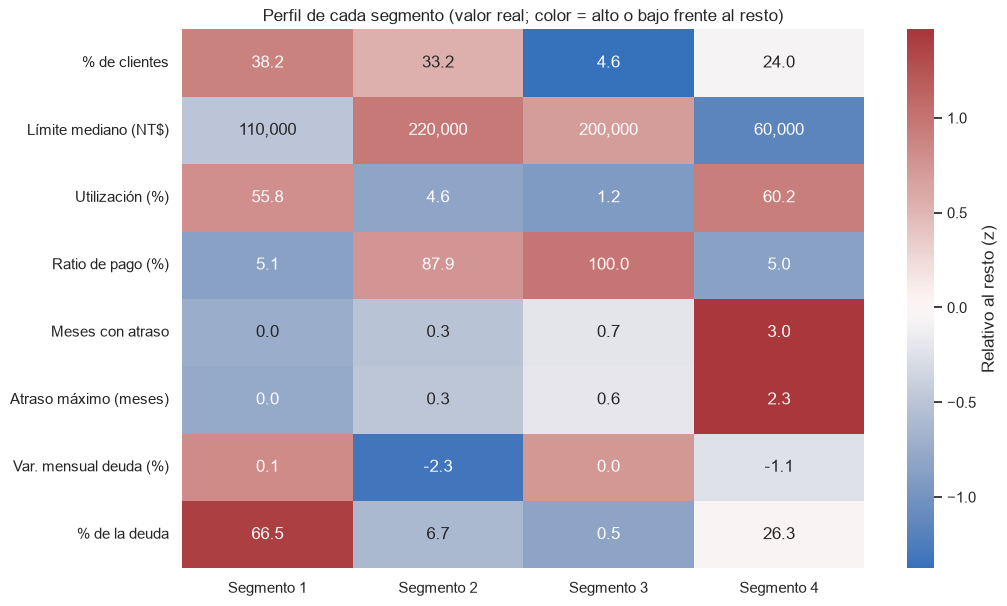

segmento,1,2,3,4
clientes,11296.0,9830.0,1355.0,7085.0
% clientes,38.2,33.2,4.6,24.0
límite mediano (NT$),110000.0,220000.0,200000.0,60000.0
utilización media (%),55.8,4.6,1.2,60.2
ratio de pago mediano (%),5.1,87.9,100.0,5.0
meses con atraso (prom.),0.0,0.3,0.7,3.0
"atraso máximo (prom., meses)",0.0,0.3,0.6,2.3
"variación mensual de deuda (mediana, %)",0.1,-2.3,0.0,-1.1
edad media,35.2,36.2,36.7,34.7
% impago,11.4,13.9,34.5,49.1


In [20]:
datos = pd.concat([limpio[['segmento', 'impago', 'AGE']], var], axis=1)
deuda_actual = deuda['BILL_AMT1']
g = datos.groupby('segmento')
perfil = pd.DataFrame({
    'clientes': g.size(),
    '% clientes': g.size() / len(datos) * 100,
    'límite mediano (NT$)': g['limite'].median(),
    'utilización media (%)': g['utilizacion'].mean() * 100,
    'ratio de pago mediano (%)': g['ratio_pago'].median() * 100,
    'meses con atraso (prom.)': g['meses_atraso'].mean(),
    'atraso máximo (prom., meses)': g['atraso_max'].mean(),
    'variación mensual de deuda (mediana, %)': g['var_deuda'].median() * 100,
    'edad media': g['AGE'].mean(),
    '% impago': g['impago'].mean() * 100,
    '% de la deuda total': deuda_actual.groupby(datos['segmento']).sum() / deuda_actual.sum() * 100,
    '% de todos los impagos': g['impago'].sum() / datos['impago'].sum() * 100,
}).round(1)
perfil.to_csv(RAIZ / 'reports' / 'perfil_segmentos.csv', encoding='utf-8')

columnas = {'% clientes': '% de clientes', 'límite mediano (NT$)': 'Límite mediano (NT$)',
            'utilización media (%)': 'Utilización (%)', 'ratio de pago mediano (%)': 'Ratio de pago (%)',
            'meses con atraso (prom.)': 'Meses con atraso', 'atraso máximo (prom., meses)': 'Atraso máximo (meses)',
            'variación mensual de deuda (mediana, %)': 'Var. mensual deuda (%)', '% de la deuda total': '% de la deuda'}
tabla = perfil[list(columnas)].rename(columns=columnas)
z = (tabla - tabla.mean()) / tabla.std()
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(z.T, annot=tabla.T.map(lambda v: f'{v:,.0f}' if abs(v) >= 1000 else f'{v:.1f}'), fmt='',
            cmap='vlag', center=0, cbar_kws={'label': 'Relativo al resto (z)'}, ax=ax,
            xticklabels=[f'Segmento {s}' for s in perfil.index])
ax.set_xlabel('')
ax.set_title('Perfil de cada segmento (valor real; color = alto o bajo frente al resto)')
guardar(fig, 's09_perfil_segmentos')
plt.show()
perfil.T

**Quiénes son** (perfil formado solo con variables de comportamiento):

| Segmento | Nombre | % clientes | Perfil | % de la deuda |
|---|---|---|---|---|
| 1 | Financiadores al día | 38.2 | Usan el 56 % de su límite, pagan solo el 5 % de lo facturado (crédito revolvente) y no se atrasan | 66.5 |
| 2 | Pagadores totales | 33.2 | Límite alto (NT$ 220 000), usan el 5 % y pagan el 88 % de lo facturado | 6.7 |
| 3 | Inactivos con atrasos | 4.6 | Casi sin deuda (1 % de uso), pero con atrasos registrados | 0.5 |
| 4 | Morosos recurrentes | 24.0 | El límite más bajo (NT$ 60 000), usan el 60 %, pagan el 5 % y tienen 3 de 6 meses con atraso | 26.3 |

## Diapositiva 10: Hallazgos del modelo y veredicto cuantitativo

Ahora sí se usa la etiqueta de impago, que no participó en el clustering, para comprobar si los segmentos difieren en riesgo.

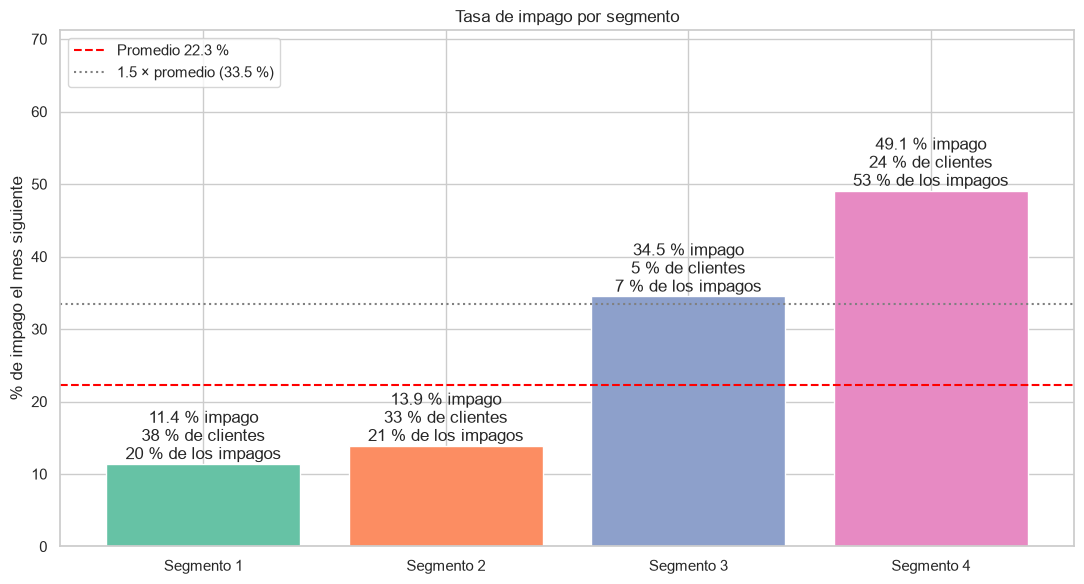

In [21]:
promedio_limpio = limpio['impago'].mean() * 100
fig, ax = plt.subplots(figsize=(11, 6))
barras = ax.bar([f'Segmento {s}' for s in perfil.index], perfil['% impago'], color=colores)
ax.axhline(promedio_limpio, color='red', linestyle='--', label=f'Promedio {promedio_limpio:.1f} %')
ax.axhline(promedio_limpio * 1.5, color='gray', linestyle=':', label=f'1.5 × promedio ({promedio_limpio * 1.5:.1f} %)')
ax.bar_label(barras, labels=[f"{t:.1f} % impago\n{c:.0f} % de clientes\n{i:.0f} % de los impagos"
                             for t, c, i in zip(perfil['% impago'], perfil['% clientes'], perfil['% de todos los impagos'])])
ax.set(ylabel='% de impago el mes siguiente', title='Tasa de impago por segmento')
ax.set_ylim(0, perfil['% impago'].max() * 1.45)
ax.legend(loc='upper left')
plt.tight_layout()
guardar(fig, 's10_impago_segmentos')
plt.show()

In [22]:
riesgo = perfil.index.max()          # segmento con mayor impago
seguro = perfil.index.min()          # segmento con menor impago
veredicto = {
    'segmento_alto_riesgo': int(riesgo),
    'alto_riesgo_pct_clientes': perfil.loc[riesgo, '% clientes'],
    'alto_riesgo_tasa_impago': perfil.loc[riesgo, '% impago'],
    'alto_riesgo_veces_promedio': round(perfil.loc[riesgo, '% impago'] / promedio_limpio, 2),
    'alto_riesgo_pct_deuda': perfil.loc[riesgo, '% de la deuda total'],
    'alto_riesgo_pct_impagos': perfil.loc[riesgo, '% de todos los impagos'],
    'segmento_bajo_riesgo': int(seguro),
    'bajo_riesgo_pct_clientes': perfil.loc[seguro, '% clientes'],
    'bajo_riesgo_tasa_impago': perfil.loc[seguro, '% impago'],
    'segmentos_sobre_1_5x': [int(s) for s in perfil.index[perfil['% impago'] >= 1.5 * promedio_limpio]],
}
resultados['veredicto'] = veredicto
resultados['perfil_segmentos'] = perfil.reset_index().to_dict(orient='records')
for clave, valor in veredicto.items():
    print(f'{clave}: {valor}')

segmento_alto_riesgo: 4
alto_riesgo_pct_clientes: 24.0
alto_riesgo_tasa_impago: 49.1
alto_riesgo_veces_promedio: 2.2
alto_riesgo_pct_deuda: 26.3
alto_riesgo_pct_impagos: 52.7
segmento_bajo_riesgo: 1
bajo_riesgo_pct_clientes: 38.2
bajo_riesgo_tasa_impago: 11.4
segmentos_sobre_1_5x: [3, 4]


| Segmento | Nombre | % impago | % de los impagos | % de la deuda | Acción sugerida |
|---|---|---|---|---|---|
| 1 | Financiadores al día | 11.4 | 19.5 | 66.5 | Núcleo rentable (deuda que paga intereses, poco impago): retener y ofrecer productos adicionales |
| 2 | Pagadores totales | 13.9 | 20.7 | 6.7 | Límite alto y poco uso: incentivar el uso con recompensas |
| 3 | Inactivos con atrasos | 34.5 | 7.1 | 0.5 | Patrón inconsistente (atrasos sin deuda): revisar las cuentas |
| 4 | Morosos recurrentes | 49.1 | 52.7 | 26.3 | Cobranza temprana, congelar límites y ofrecer refinanciación |

**Veredicto:**
- El **segmento 4 tiene 2.2 veces la tasa de impago promedio** (49.1 % frente a 22.3 %). Con el 24 % de los clientes concentra el **52.7 % de todos los impagos** y el **26.3 % de la deuda** (objetivos 2 y 3 cumplidos).
- El segmento 3 también supera 1.5 veces el promedio (34.5 %), pero solo pesa el 0.5 % de la deuda.
- El impago **no se usó** para formar los segmentos. Que difieran tanto en riesgo (de 11.4 % a 49.1 %) confirma que la segmentación por comportamiento tiene valor de negocio.

## Diapositiva 11: Conclusiones y próximos pasos

**Conclusiones:**
1. **Limpieza:** los datos parecían limpios (0 nulos), pero tenían 399 códigos fuera del diccionario y 35 duplicados. Al eliminarlos (1.45 % de las filas) la tasa de impago solo pasó de 22.1 % a 22.3 %.
2. **Método:** se eligió clustering con K-Means porque entrega un segmento por cliente, que se puede convertir en una política, y porque procesa a los 29 566 clientes. El jerárquico necesitaría unos 3.5 GB solo para las distancias.
3. **Segmentación:** con 4 segmentos (silueta 0.347), concentrar la cobranza en el 24 % de los clientes (segmento 4) cubre más de la mitad de los impagos.

**Próximos pasos para el Avance 2 (modelos supervisados):**
- Entrenar un **clasificador de impago** (regresión logística, árbol, Random Forest) con validación cruzada, usando el segmento como variable adicional.
- Medir si el segmento mejora la predicción frente a un modelo sin él.
- Evaluar con **recall** y **AUC**, porque para el banco es más caro no detectar un impago que revisar a un cliente de más.

In [23]:
salida = pd.concat([limpio, var.add_prefix('var_')], axis=1)
salida.to_csv(PROCESADOS / 'clientes_segmentados.csv', index=False)

with open(RAIZ / 'reports' / 'resultados.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('Figuras generadas:', sorted(p.name for p in FIGURAS.glob('*.png')))
print('Archivos: reports/resultados.json, reports/perfil_segmentos.csv, data/processed/clientes_segmentados.csv')

Figuras generadas: ['s04_categoricas.png', 's04_distribuciones.png', 's05_correlacion.png', 's05_dispersion.png', 's05_impago_por_grupo.png', 's06_faltantes.png', 's07_atipicos_transformacion.png', 's07_escalado_variacion.png', 's08_codo_silueta.png', 's09_perfil_segmentos.png', 's09_segmentos.png', 's10_impago_segmentos.png']
Archivos: reports/resultados.json, reports/perfil_segmentos.csv, data/processed/clientes_segmentados.csv
